# Zadanie 10 – Zużycie zasobów przez modele ML

Symulujemy 50 pomiarów (5 modeli × 10) zużycia zasobów podczas treningu, liczymy średnie i sprawdzamy, który model jest najbardziej energooszczędny.

## 1. Generowanie datasetu

Dla każdego modelu zadajemy typowy profil (czas treningu, CPU, RAM, moc) i dodajemy losowy szum. Energia zależy od czasu i obciążenia CPU: `czas [h] × moc [kW] × (cpu / cpu_typowe)`. Ziarno generatora (`seed=42`) zapewnia powtarzalność wyników.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# typowy czas [min], CPU [%], RAM [GB], średnia moc [kW]
profiles = {
    "Linear Regression": dict(t=2,   cpu=25, ram=1.0,  kw=0.05),
    "Random Forest":     dict(t=15,  cpu=70, ram=4.0,  kw=0.12),
    "XGBoost":           dict(t=10,  cpu=65, ram=3.0,  kw=0.10),
    "CNN":               dict(t=60,  cpu=85, ram=8.0,  kw=0.25),
    "Transformer":       dict(t=120, cpu=90, ram=16.0, kw=0.35),
}

rows = []
for name, p in profiles.items():
    for _ in range(10):
        t = max(0.5, rng.normal(p["t"], p["t"] * 0.15))
        cpu = float(np.clip(rng.normal(p["cpu"], 5), 5, 100))
        ram = max(0.2, rng.normal(p["ram"], p["ram"] * 0.1))
        energy = max(0.0001, t / 60 * p["kw"] * (cpu / p["cpu"]) * rng.normal(1, 0.05))
        rows.append((name, round(t, 1), round(cpu, 1), round(ram, 2), round(energy, 4)))

df = pd.DataFrame(rows, columns=["model_name", "training_time_min", "cpu_percent", "ram_gb", "energy_kwh"])
print(df.shape)
df.head(12)

(50, 5)


,model_name,training_time_min,cpu_percent,ram_gb,energy_kwh
0,Linear Regression,2.1,19.8,1.08,0.0014
1,Linear Regression,1.4,18.5,1.01,0.0009
2,Linear Regression,2.0,20.7,1.09,0.0014
3,Linear Regression,2.0,30.6,1.05,0.0020
4,Linear Regression,2.1,20.2,1.09,0.0014
5,Linear Regression,1.9,21.6,1.12,0.0014
6,Linear Regression,1.9,23.2,1.05,0.0015
7,Linear Regression,2.1,27.2,1.21,0.0019
8,Linear Regression,1.8,20.9,1.06,0.0014
9,Linear Regression,2.0,20.8,0.92,0.0014


## 2. Średnie zużycie dla każdego modelu

In [2]:
means = (
    df.groupby("model_name")
      .mean()
      .round(4)
      .sort_values("energy_kwh")
)
means

,training_time_min,cpu_percent,ram_gb,energy_kwh
model_name,,,,
Linear Regression,1.93,22.35,1.068,0.0015
XGBoost,9.57,63.57,2.979,0.0154
Random Forest,14.62,71.46,3.939,0.0300
CNN,59.31,84.75,7.869,0.2464
Transformer,122.64,90.88,16.223,0.7191


## 3. Który model jest najbardziej energooszczędny?

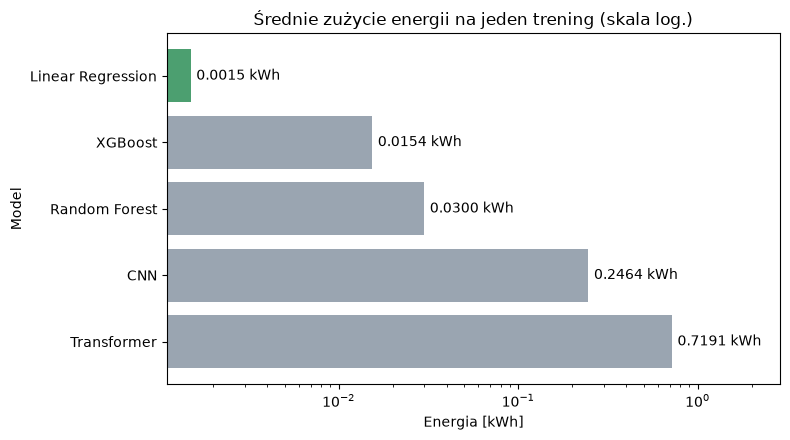

In [3]:
energy = means["energy_kwh"]
colors = ["#4C9F70" if m == energy.idxmin() else "#9AA5B1" for m in energy.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(energy.index, energy.values, color=colors)
ax.bar_label(bars, labels=[f"{v:.4f} kWh" for v in energy.values], padding=4)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlim(right=energy.max() * 4)
ax.set_title("Średnie zużycie energii na jeden trening (skala log.)")
ax.set_xlabel("Energia [kWh]")
ax.set_ylabel("Model")
fig.tight_layout()
plt.show()

## 4. Wnioski

- **Najbardziej energooszczędny jest Linear Regression** – średnio zaledwie ok. **0,0015 kWh** na trening (ok. 2 min, 22% CPU, ok. 1 GB RAM).
- **Najbardziej energochłonny jest Transformer** – ok. **0,72 kWh** na trening, czyli prawie **480 razy więcej** niż regresja liniowa. Trenuje też najdłużej (ok. 123 min) i potrzebuje najwięcej RAM (ok. 16 GB).
- **Kolejność zużycia energii:** Linear Regression < XGBoost < Random Forest < CNN < Transformer. Wraz ze złożonością modelu rosną jednocześnie czas treningu, obciążenie CPU i zapotrzebowanie na RAM.
- **Modele drzewiaste:** XGBoost zużywa ok. 2 razy mniej energii niż Random Forest (0,0154 vs 0,0300 kWh) przy krótszym treningu, więc przy podobnej jakości jest rozsądnym wyborem.
- **Sieci neuronowe są o rząd wielkości droższe** od modeli klasycznych: CNN zużywa ok. 0,25 kWh, a Transformer jest od niego prawie 3 razy bardziej kosztowny.
- **Zastrzeżenie:** dane są symulowane, a energia mierzy koszt jednego treningu, nie jakość modelu. W praktyce wybór modelu powinien uwzględniać kompromis między dokładnością a zużyciem zasobów.
